# Ensemble Learning for Scam Conversation Detection

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    VotingClassifier,
    StackingClassifier,
    BaggingClassifier,
    AdaBoostClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv("../datasets/processed/cleaned_train.csv")

print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df[["cleaned_text", "label"]].isnull().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nUnique labels:")
print(df["label"].unique())

Dataset shape: (30409, 3)

First five rows:


,text,label,cleaned_text
0,hello this is the national lottery center cong...,1,hello this is the national lottery center cong...
1,i am a traffic consultation assistant i can he...,1,i am a traffic consultation assistant i can he...
2,sez hows u de arab boy hope u r all good give ...,0,sez hows u de arab boy hope u r all good give ...
3,i like to travel domestically or international...,0,i like to travel domestically or international...
4,welcome are there any products you would like ...,1,welcome are there any products you would like ...



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 30409 entries, 0 to 30408
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   text          30409 non-null  str  
 1   label         30409 non-null  int64
 2   cleaned_text  30409 non-null  str  
dtypes: int64(1), str(2)
memory usage: 712.8 KB

Missing values:
cleaned_text    0
label           0
dtype: int64

Label distribution:
label
1    19379
0    11030
Name: count, dtype: int64

Unique labels:
[1 0]


## Dataset Class distribution graph

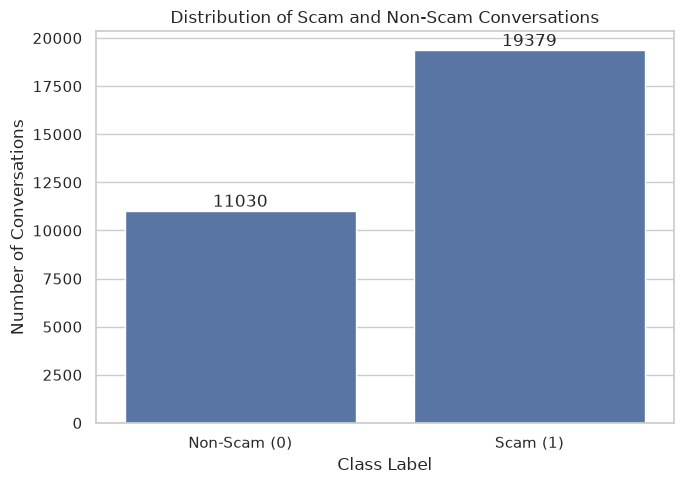

In [5]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="label"
)

plt.title("Distribution of Scam and Non-Scam Conversations")
plt.xlabel("Class Label")
plt.ylabel("Number of Conversations")
plt.xticks([0, 1], ["Non-Scam (0)", "Scam (1)"])

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [6]:
X = df["cleaned_text"].fillna("")
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 24327
Testing samples: 6082

Training label distribution:
label
1    15503
0     8824
Name: count, dtype: int64

Testing label distribution:
label
1    3876
0    2206
Name: count, dtype: int64


In [7]:
vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)

X_test_tfidf = vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (24327, 10000)
Testing TF-IDF shape: (6082, 10000)


# Baseline Models that were used last time for classification and regression

In [8]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC()
}

baseline_predictions = {}

for name, model in baseline_models.items():

    model.fit(X_train_tfidf, y_train)

    predictions = model.predict(X_test_tfidf)

    baseline_predictions[name] = predictions

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, pos_label=1, zero_division=0))
    print("Recall:", recall_score(y_test, predictions, pos_label=1, zero_division=0))
    print("F1 Score:", f1_score(y_test, predictions, pos_label=1, zero_division=0))

    print("\nClassification Report:")
    print(classification_report(y_test, predictions, zero_division=0))


Logistic Regression
Accuracy: 0.9886550476816837
Precision: 0.9945440374123149
Recall: 0.9876160990712074
F1 Score: 0.9910679611650486

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      2206
           1       0.99      0.99      0.99      3876

    accuracy                           0.99      6082
   macro avg       0.99      0.99      0.99      6082
weighted avg       0.99      0.99      0.99      6082


Naive Bayes
Accuracy: 0.9506741203551463
Precision: 0.9558898521162672
Recall: 0.967234262125903
F1 Score: 0.9615285970761733

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      2206
           1       0.96      0.97      0.96      3876

    accuracy                           0.95      6082
   macro avg       0.95      0.94      0.95      6082
weighted avg       0.95      0.95      0.95      6082


Linear SVM
Accuracy: 0.99424531404

# Ensemble-1 VOTING CLASSIFIER

## Hard voting

In [9]:
hard_voting = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("nb", MultinomialNB()),
        ("svm", LinearSVC())
    ],
    voting="hard"
)

hard_voting.fit(X_train_tfidf, y_train)

hard_voting_pred = hard_voting.predict(X_test_tfidf)

print("HARD VOTING CLASSIFIER")
print("----------------------")

print("Accuracy:", accuracy_score(y_test, hard_voting_pred))
print("Precision:", precision_score(y_test, hard_voting_pred, pos_label=1, zero_division=0))
print("Recall:", recall_score(y_test, hard_voting_pred, pos_label=1, zero_division=0))
print("F1 Score:", f1_score(y_test, hard_voting_pred, pos_label=1, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, hard_voting_pred, zero_division=0))

HARD VOTING CLASSIFIER
----------------------
Accuracy: 0.9901348240710293
Precision: 0.9950700570835496
Recall: 0.989422084623323
F1 Score: 0.9922380336351876

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2206
           1       1.00      0.99      0.99      3876

    accuracy                           0.99      6082
   macro avg       0.99      0.99      0.99      6082
weighted avg       0.99      0.99      0.99      6082



## Soft Voting

In [10]:
soft_voting = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("nb", MultinomialNB())
    ],
    voting="soft"
)

soft_voting.fit(X_train_tfidf, y_train)

soft_voting_pred = soft_voting.predict(X_test_tfidf)

print("SOFT VOTING CLASSIFIER")
print("----------------------")

print("Accuracy:", accuracy_score(y_test, soft_voting_pred))
print("Precision:", precision_score(y_test, soft_voting_pred, pos_label=1, zero_division=0))
print("Recall:", recall_score(y_test, soft_voting_pred, pos_label=1, zero_division=0))
print("F1 Score:", f1_score(y_test, soft_voting_pred, pos_label=1, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, soft_voting_pred, zero_division=0))

SOFT VOTING CLASSIFIER
----------------------
Accuracy: 0.9802696481420585
Precision: 0.9875389408099688
Recall: 0.9814241486068112
F1 Score: 0.984472049689441

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.97      2206
           1       0.99      0.98      0.98      3876

    accuracy                           0.98      6082
   macro avg       0.98      0.98      0.98      6082
weighted avg       0.98      0.98      0.98      6082



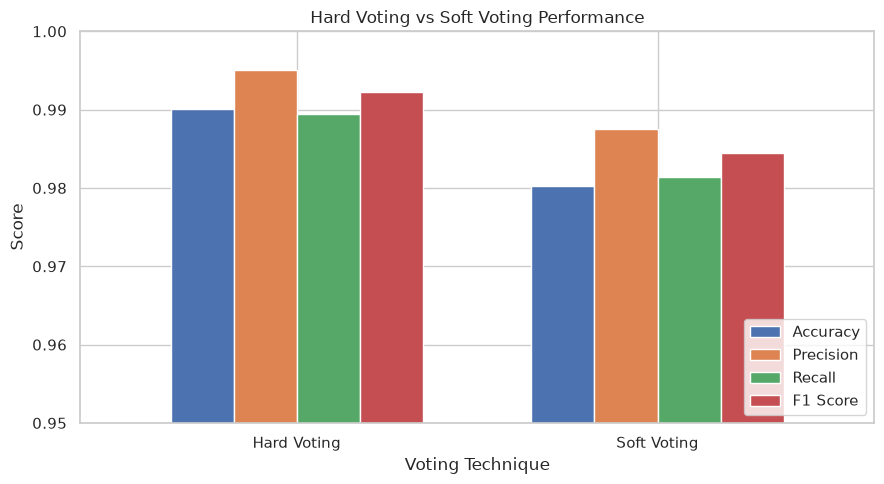

In [12]:
voting_results.set_index("Voting Type").plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Hard Voting vs Soft Voting Performance")
plt.ylabel("Score")
plt.xlabel("Voting Technique")

plt.ylim(0.95, 1.00)  # Zoomed Y-axis scale

plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Ensemble-2 STACKING CLASSIFIER

In [17]:
stacking_model = StackingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("nb", MultinomialNB()),
        ("svm", LinearSVC())
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    n_jobs=-1
)

stacking_model.fit(X_train_tfidf, y_train)

stacking_pred = stacking_model.predict(X_test_tfidf)

print("STACKING CLASSIFIER")
print("-------------------")

print("Accuracy:", accuracy_score(y_test, stacking_pred))
print("Precision:", precision_score(y_test, stacking_pred, pos_label=1, zero_division=0))
print("Recall:", recall_score(y_test, stacking_pred, pos_label=1, zero_division=0))
print("F1 Score:", f1_score(y_test, stacking_pred, pos_label=1, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, stacking_pred, zero_division=0))

STACKING CLASSIFIER
-------------------
Accuracy: 0.9939164748438014
Precision: 0.9974086550919927
Recall: 0.9930340557275542
F1 Score: 0.9952165481577246

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2206
           1       1.00      0.99      1.00      3876

    accuracy                           0.99      6082
   macro avg       0.99      0.99      0.99      6082
weighted avg       0.99      0.99      0.99      6082



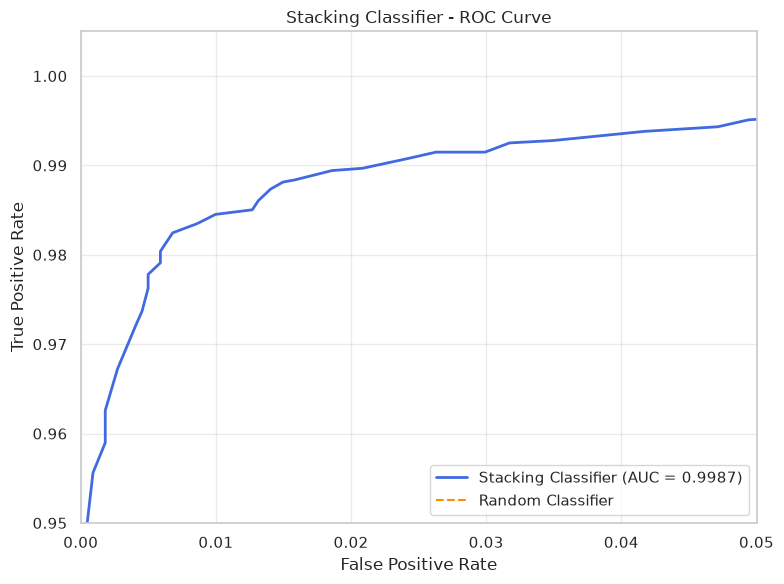

In [33]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    color="royalblue",
    label=f"Stacking Classifier (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="darkorange",
    label="Random Classifier"
)

plt.title("Stacking Classifier - ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

# Zoomed axes
plt.xlim(0, 0.05)
plt.ylim(0.95, 1.005)

plt.xticks(np.arange(0, 0.051, 0.01))
plt.yticks(np.arange(0.95, 1.001, 0.01))

plt.legend(loc="lower right")
plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

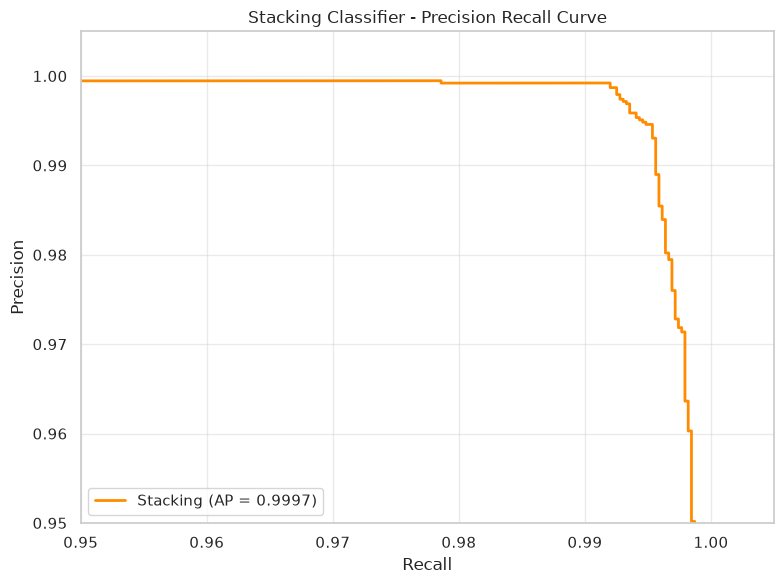

In [31]:
plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    linewidth=2,
    color="darkorange",
    label=f"Stacking (AP = {ap_score:.4f})"
)

plt.title("Stacking Classifier - Precision Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")

# Zoomed axes
plt.xlim(0.95, 1.005)
plt.ylim(0.95, 1.005)

plt.xticks(np.arange(0.95, 1.001, 0.01))
plt.yticks(np.arange(0.95, 1.001, 0.01))

plt.legend(loc="lower left")
plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

# Ensemble-3 BAGGING CLASSIFIER

In [14]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=50,
    max_samples=0.8,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train_tfidf, y_train)

bagging_pred = bagging_model.predict(X_test_tfidf)

print("BAGGING CLASSIFIER")
print("------------------")

print("Accuracy:", accuracy_score(y_test, bagging_pred))
print("Precision:", precision_score(y_test, bagging_pred, pos_label=1, zero_division=0))
print("Recall:", recall_score(y_test, bagging_pred, pos_label=1, zero_division=0))
print("F1 Score:", f1_score(y_test, bagging_pred, pos_label=1, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, bagging_pred, zero_division=0))

BAGGING CLASSIFIER
------------------
Accuracy: 0.9868464320947057
Precision: 0.9909467149508536
Recall: 0.9883900928792569
F1 Score: 0.9896667527770602

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      2206
           1       0.99      0.99      0.99      3876

    accuracy                           0.99      6082
   macro avg       0.99      0.99      0.99      6082
weighted avg       0.99      0.99      0.99      6082



In [23]:
estimator_counts = [5, 10, 20, 30, 50]
bagging_scores = []

for count in estimator_counts:

    model = BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=count,
        max_samples=0.8,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_tfidf, y_train)

    predictions = model.predict(X_test_tfidf)

    score = f1_score(y_test, predictions, zero_division=0)

    bagging_scores.append(score)

    print(f"Estimators: {count}, F1 Score: {score:.4f}")

Estimators: 5, F1 Score: 0.9841
Estimators: 10, F1 Score: 0.9858
Estimators: 20, F1 Score: 0.9861
Estimators: 30, F1 Score: 0.9879
Estimators: 50, F1 Score: 0.9897


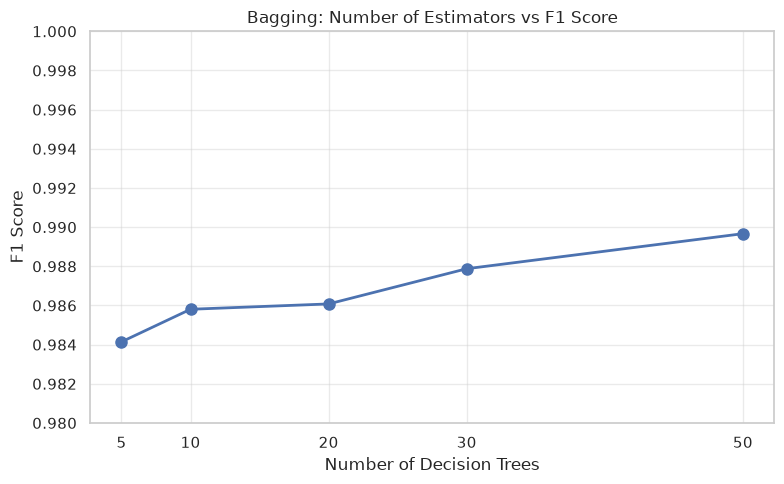

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    estimator_counts,
    bagging_scores,
    marker="o",
    linewidth=2,
    markersize=8
)

plt.title("Bagging: Number of Estimators vs F1 Score")
plt.xlabel("Number of Decision Trees")
plt.ylabel("F1 Score")

plt.ylim(0.98, 1.00)
plt.yticks(np.arange(0.98, 1.001, 0.002))

plt.xticks(estimator_counts)
plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

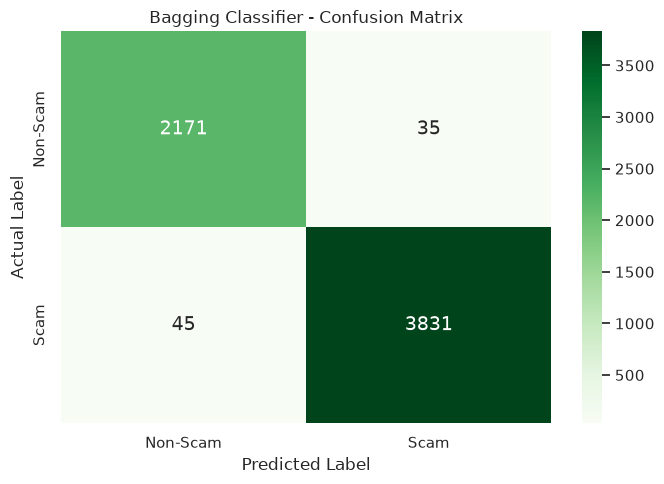

In [25]:
plt.figure(figsize=(7, 5))

cm = confusion_matrix(
    y_test,
    bagging_pred,
    labels=[0, 1]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Non-Scam", "Scam"],
    yticklabels=["Non-Scam", "Scam"],
    annot_kws={"size": 14}
)

plt.title("Bagging Classifier - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

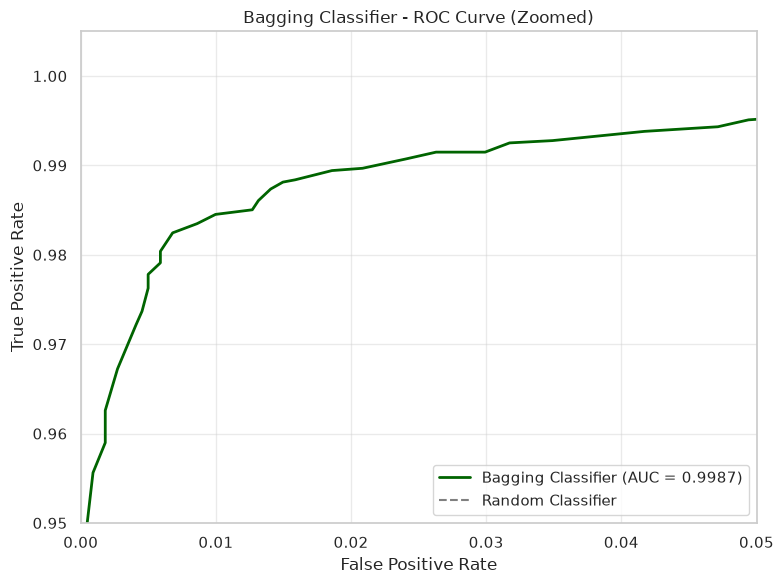

In [29]:
bagging_scores = bagging_model.predict_proba(X_test_tfidf)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    bagging_scores,
    pos_label=1
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    color="darkgreen",
    label=f"Bagging Classifier (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("Bagging Classifier - ROC Curve (Zoomed)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

# Zoomed axes
plt.xlim(0, 0.05)
plt.ylim(0.95, 1.005)

plt.xticks(np.arange(0, 0.051, 0.01))
plt.yticks(np.arange(0.95, 1.001, 0.01))

plt.legend(loc="lower right")
plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

# Ensemble-4 AdaBoost Classifier

In [27]:
adaboost_model = AdaBoostClassifier(
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

adaboost_model.fit(X_train_tfidf, y_train)

adaboost_pred = adaboost_model.predict(X_test_tfidf)

print("ADABOOST CLASSIFIER")
print("-------------------")

print("Accuracy:", accuracy_score(y_test, adaboost_pred))
print("Precision:", precision_score(y_test, adaboost_pred, pos_label=1, zero_division=0))
print("Recall:", recall_score(y_test, adaboost_pred, pos_label=1, zero_division=0))
print("F1 Score:", f1_score(y_test, adaboost_pred, pos_label=1, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, adaboost_pred, zero_division=0))

ADABOOST CLASSIFIER
-------------------
Accuracy: 0.9584018414995067
Precision: 0.9778422579794249
Recall: 0.9563983488132095
F1 Score: 0.9670014347202296

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.96      0.94      2206
           1       0.98      0.96      0.97      3876

    accuracy                           0.96      6082
   macro avg       0.95      0.96      0.96      6082
weighted avg       0.96      0.96      0.96      6082



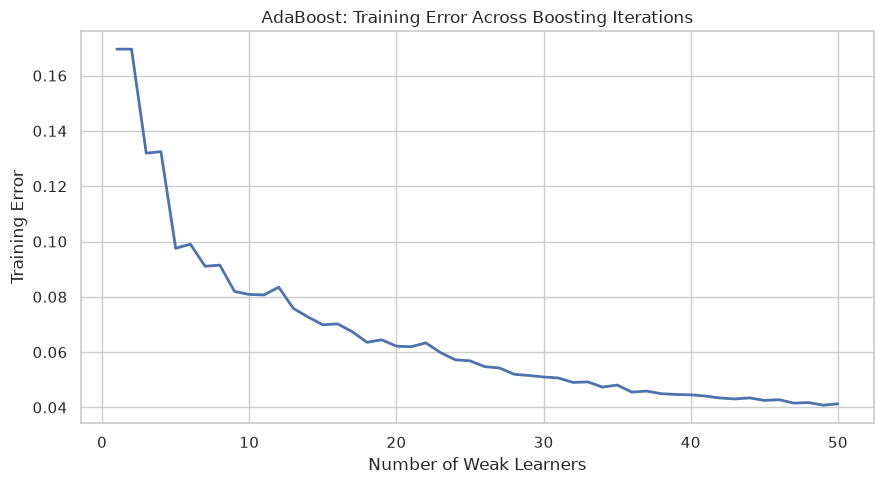

In [28]:
staged_train_errors = []

for predictions in adaboost_model.staged_predict(X_train_tfidf):

    error = 1 - accuracy_score(y_train, predictions)

    staged_train_errors.append(error)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(staged_train_errors) + 1),
    staged_train_errors,
    linewidth=2
)

plt.title("AdaBoost: Training Error Across Boosting Iterations")
plt.xlabel("Number of Weak Learners")
plt.ylabel("Training Error")
plt.tight_layout()
plt.show()  

# COMPARISIONS AND GRAPHS

In [36]:
all_predictions = {
    "Logistic Regression": baseline_predictions["Logistic Regression"],
    "Naive Bayes": baseline_predictions["Naive Bayes"],
    "Linear SVM": baseline_predictions["Linear SVM"],
    "Hard Voting": hard_voting_pred,
    "Soft Voting": soft_voting_pred,
    "Stacking": stacking_pred,
    "Bagging": bagging_pred,
    "AdaBoost": adaboost_pred
}

results = []

for name, predictions in all_predictions.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, predictions, pos_label=1, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, pos_label=1, zero_division=0)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.9942,0.9984,0.9925,0.9955
1,Stacking,0.9939,0.9974,0.9930,0.9952
2,Hard Voting,0.9901,0.9951,0.9894,0.9922
3,Logistic Regression,0.9887,0.9945,0.9876,0.9911
4,Bagging,0.9868,0.9909,0.9884,0.9897
5,Soft Voting,0.9803,0.9875,0.9814,0.9845
6,AdaBoost,0.9584,0.9778,0.9564,0.9670
7,Naive Bayes,0.9507,0.9559,0.9672,0.9615


In [37]:
best_model = results_df.iloc[0]

print("BEST PERFORMING MODEL")
print("---------------------")

print("Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))

BEST PERFORMING MODEL
---------------------
Model: Linear SVM
Accuracy: 0.9942
Precision: 0.9984
Recall: 0.9925
F1 Score: 0.9955


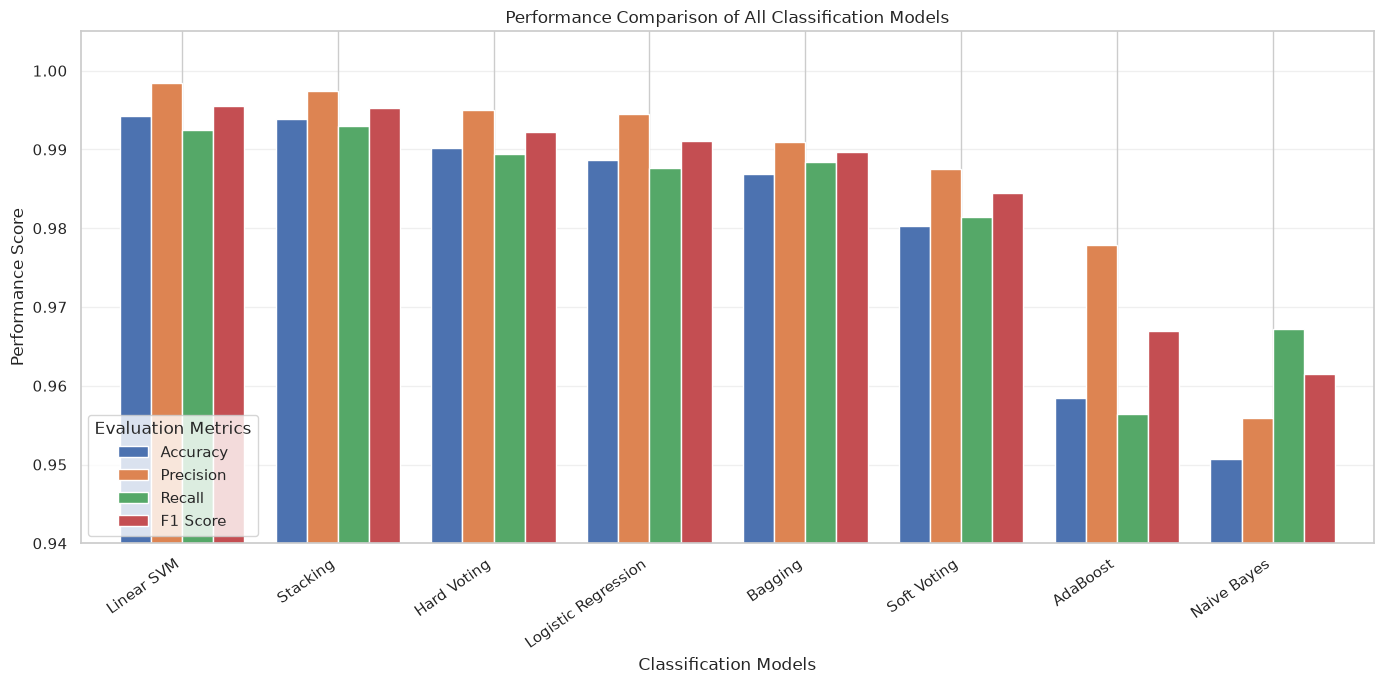

In [45]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

ax = results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Performance Comparison of All Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Performance Score")

plt.ylim(0.94, 1.005)
plt.yticks(np.arange(0.94, 1.001, 0.01))

plt.xticks(rotation=35, ha="right")
plt.legend(title="Evaluation Metrics", loc="lower left")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

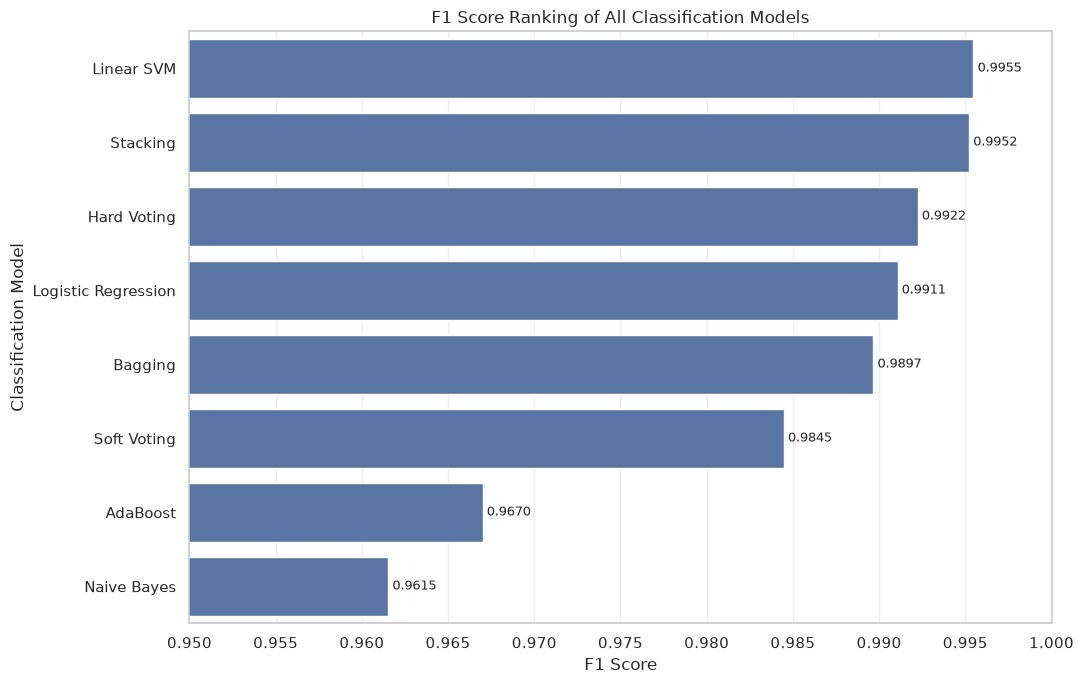

In [46]:
plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=results_df,
    x="F1 Score",
    y="Model"
)

plt.title("F1 Score Ranking of All Classification Models")
plt.xlabel("F1 Score")
plt.ylabel("Classification Model")

plt.xlim(0.95, 1.00)
plt.xticks(np.arange(0.95, 1.001, 0.005))

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3, fontsize=9)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

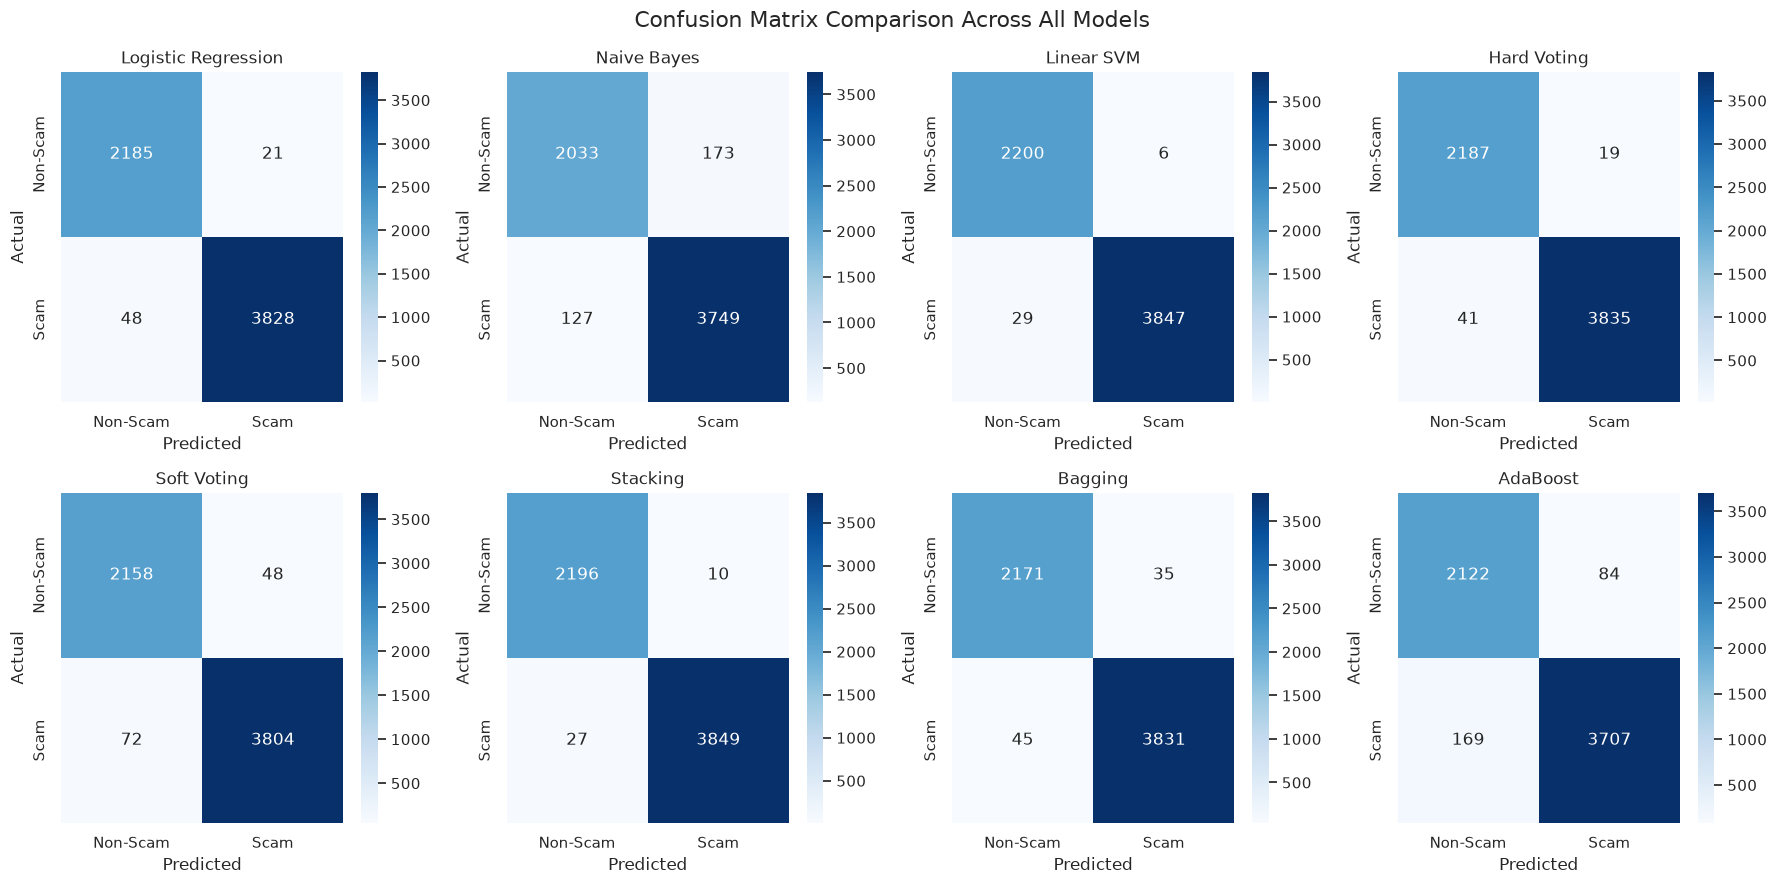

In [40]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for ax, (name, predictions) in zip(axes.flat, all_predictions.items()):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-Scam", "Scam"],
        yticklabels=["Non-Scam", "Scam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Confusion Matrix Comparison Across All Models", fontsize=16)
plt.tight_layout()
plt.show()

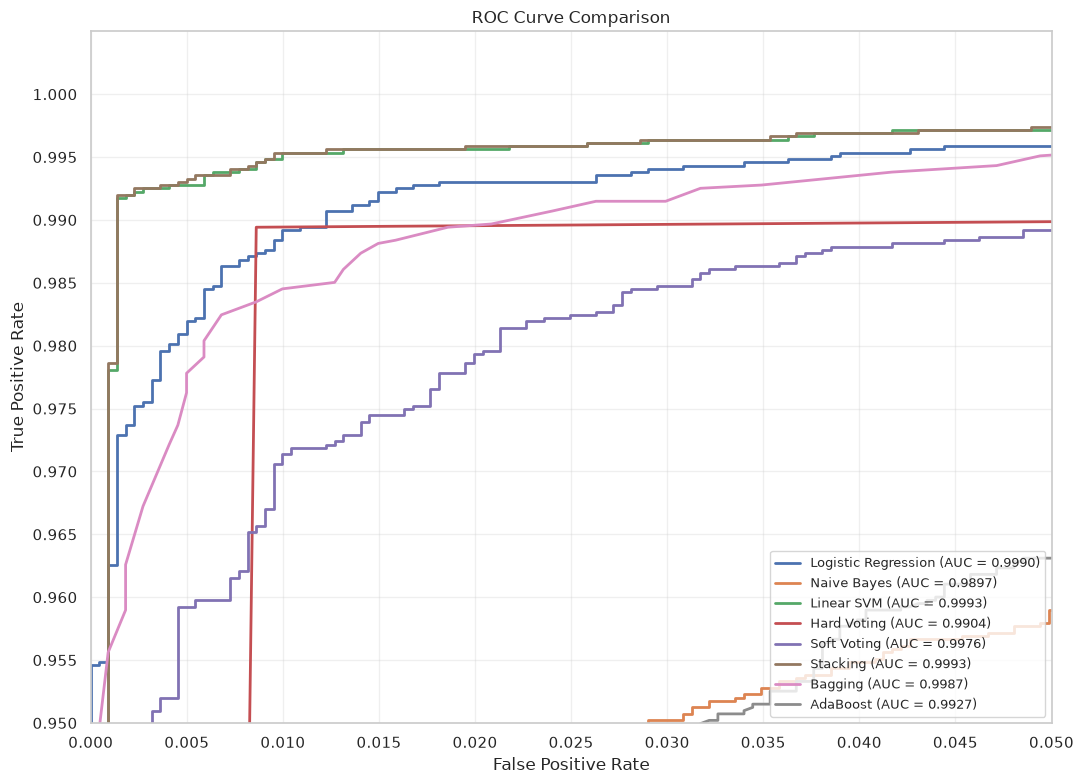

In [47]:
plt.figure(figsize=(11, 8))

for name, model in models_for_roc.items():

    y_scores = get_positive_scores(model, X_test_tfidf)

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_scores,
        pos_label=1
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.xlim(0, 0.05)
plt.ylim(0.95, 1.005)

plt.xticks(np.arange(0, 0.051, 0.005))
plt.yticks(np.arange(0.95, 1.001, 0.005))

plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

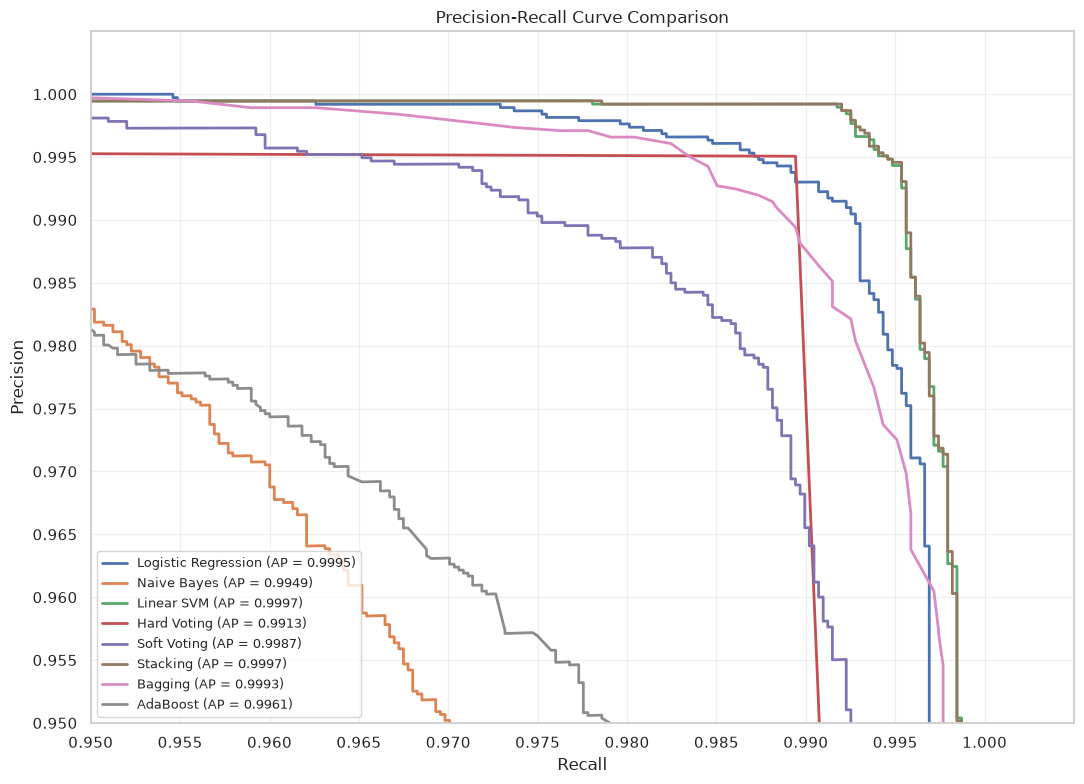

In [49]:
plt.figure(figsize=(11, 8))

for name, model in models_for_roc.items():

    y_scores = get_positive_scores(model, X_test_tfidf)

    precision_values, recall_values, thresholds = precision_recall_curve(
        y_test,
        y_scores,
        pos_label=1
    )

    ap = average_precision_score(
        y_test,
        y_scores,
        pos_label=1
    )

    plt.plot(
        recall_values,
        precision_values,
        linewidth=2,
        label=f"{name} (AP = {ap:.4f})"
    )

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.xlim(0.95, 1.005)
plt.ylim(0.95, 1.005)

plt.xticks(np.arange(0.95, 1.001, 0.005))
plt.yticks(np.arange(0.95, 1.001, 0.005))

plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

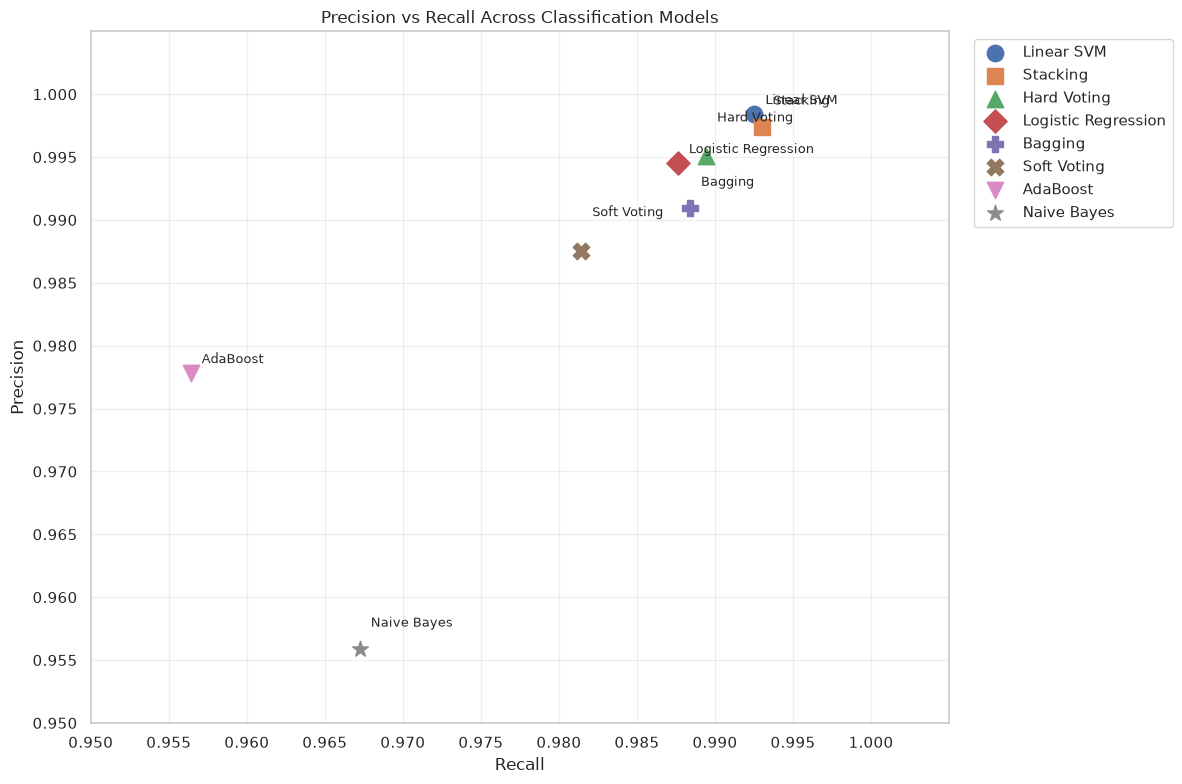

In [50]:
plt.figure(figsize=(12, 8))

markers = ["o", "s", "^", "D", "P", "X", "v", "*"]

for i, (_, row) in enumerate(results_df.iterrows()):

    plt.scatter(
        row["Recall"],
        row["Precision"],
        s=140,
        marker=markers[i],
        label=row["Model"]
    )

    plt.annotate(
        row["Model"],
        (row["Recall"], row["Precision"]),
        xytext=(8, 7 + (i % 3) * 9),
        textcoords="offset points",
        fontsize=9
    )

plt.title("Precision vs Recall Across Classification Models")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.xlim(0.95, 1.005)
plt.ylim(0.95, 1.005)

plt.xticks(np.arange(0.95, 1.001, 0.005))
plt.yticks(np.arange(0.95, 1.001, 0.005))

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()